# Chapter 12 – Example 12.3

## Mechanism Synthesis Publications Timeline (1990–2025)

**Objective:** Model and visualize the growth of publications in mechanism synthesis using Genetic Algorithms (GA) and neural networks. Calculate the Compound Annual Growth Rate (CAGR) and identify key periods of technological evolution.

### 1. Growth Model

In [4]:
from numpy import *
import builtins

anios = arange(1990, 2026)

# Model components
base = 2 + 0.3 * (anios - 1990)
pico_ga = 8 * exp(-0.5 * ((anios - 2003) / 4) ** 2)    # GA boom ≈ 2000-2006
pico_nn = 15 * exp(-0.5 * ((anios - 2018) / 3) ** 2)   # deep learning boom
pico_hyb = 10 * exp(-0.5 * ((anios - 2021) / 3) ** 2)  # hybrid approaches

publicaciones = around(base + pico_ga + pico_nn + pico_hyb + 1).astype(int)

# Statistics
total = publicaciones.sum()
cagr = (publicaciones[-1] / publicaciones[0]) ** (1 / (len(anios) - 1)) - 1
idx_p = argmax(publicaciones)
p2015 = publicaciones[anios >= 2015].sum()

print("Publication Analysis 1990–2025")
print(f"{'='*40}")
print(f"Cumulative Total:        {total} publications")
print(f"CAGR (1990→2025):        {100*cagr:.1f}% annually")
print(f"Peak Year:               {anios[idx_p]} ({publicaciones[idx_p]} pub.)")
print(f"Publications 2015–2025:  {p2015} ({100*p2015/total:.1f}% of total)")
print()

print("Publications per decade:")
for inicio in [1990, 2000, 2010, 2020]:
    fin = builtins.min(inicio + 10, 2026)
    mask = (anios >= inicio) & (anios < fin)
    print(f"  {inicio}s: {publicaciones[mask].sum():>4} pub. "
          f"(mean {publicaciones[mask].mean():.1f}/year)")

Publication Analysis 1990–2025
Cumulative Total:        557 publications
CAGR (1990→2025):        5.4% annually
Peak Year:               2019 (34 pub.)
Publications 2015–2025:  298 (53.5% of total)

Publications per decade:
  1990s:   60 pub. (mean 6.0/year)
  2000s:  134 pub. (mean 13.4/year)
  2010s:  206 pub. (mean 20.6/year)
  2020s:  157 pub. (mean 26.2/year)


### 2. Stacked Area Chart Visualization

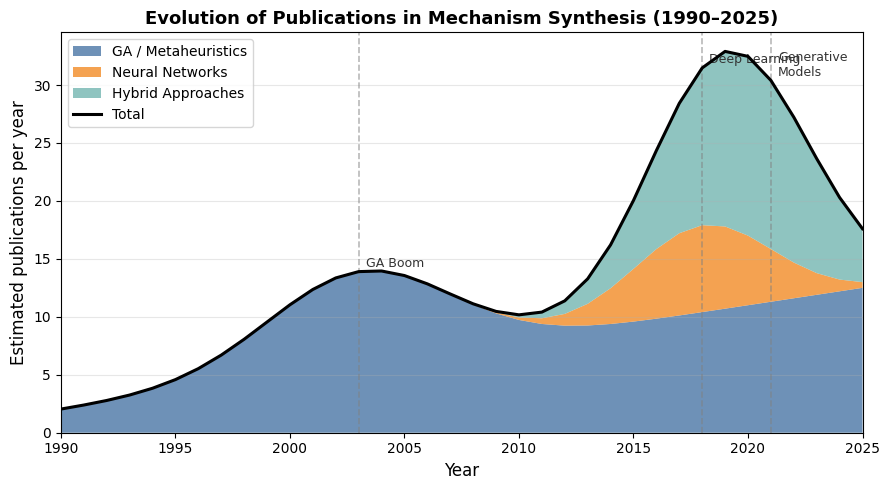

In [5]:
import matplotlib.pyplot as plt

# Correcting the component definitions to avoid syntax errors and mismatching names
ga_only  = base + pico_ga
nn_only  = 0.5 * pico_nn
hybrid   = 0.5 * pico_nn + pico_hyb
total_v  = ga_only + nn_only + hybrid

fig, ax = plt.subplots(figsize=(9, 5))
ax.stackplot(anios, ga_only, nn_only, hybrid,
             labels=['GA / Metaheuristics', 'Neural Networks', 'Hybrid Approaches'],
             colors=['#4e79a7', '#f28e2b', '#76b7b2'], alpha=0.82)
ax.plot(anios, total_v, 'k-', linewidth=2.2, label='Total', zorder=5)

# Milestones
for yr, txt in {2003:'GA Boom', 2018:'Deep Learning', 2021:'Generative\nModels'}.items():
    ax.axvline(yr, color='gray', ls='--', alpha=0.55, lw=1.2)
    ax.text(yr+0.3, total_v[yr-1990]+0.4, txt, fontsize=9, color='#333')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Estimated publications per year', fontsize=12)
ax.set_title('Evolution of Publications in Mechanism Synthesis (1990–2025)',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.set_xlim(1990, 2025); ax.set_ylim(0, None)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig12_3_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. Projection for the 2026–2030 Period

In [6]:
# Simple projection based on recent trend
anios_fut = arange(2025, 2031)

# Continuity model: hybrid post-peak moderate growth
base_fut = publicaciones[-1] + 1.5 * (anios_fut - 2025)
decay_hyb = 5 * exp(-0.5 * ((anios_fut - 2023) / 3) ** 2)
proyeccion = around(base_fut + decay_hyb).astype(int)

print("Estimated Projection of Publications 2026–2030")
print(f"{'Year':>6}  {'Est. Pubs':>15}  {'Cumulative':>10}")

acum = total
for yr, pub in zip(anios_fut, proyeccion):
    acum += pub
    print(f"{yr:>6}  {pub:>15}  {acum:>10}")

print("\nNote: Simplified projection; subject to technological shifts.")

Estimated Projection of Publications 2026–2030
  Year        Est. Pubs  Cumulative
  2025               23         580
  2026               24         604
  2027               24         628
  2028               25         653
  2029               26         679
  2030               27         706

Note: Simplified projection; subject to technological shifts.
